In [45]:
import json
import glob
import os

import cv2
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

from utils import calibrate, undistort, undistort_upd, calibrate_robust

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [67]:
with open("fovs.json", "r") as f:
    FOVs = json.load(f)

FOV_X = FOVs["cam4.2"]["v"]
FOV_Y = FOVs["cam4.2"]["h"]

In [63]:
imgs = []
idx = 2
for i in glob.glob(f"data/calibCam4/{idx}/*.tif"):
    img = cv2.imread(i)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    imgs.append(img)

print(len(imgs))

np.random.seed(42)
np.random.shuffle(imgs)
imgs = imgs[:30]
try:
    K, D, DIM = calibrate(imgs)
    
except Exception as e:
    print("error in calibration")
    print(e)

with open(os.path.join("params", f"cam4_2_{idx}_rev_b" + ".json"), "w") as f:
    json.dump({
        "IMG_W": DIM[0],
        "IMG_H": DIM[1],
        "LENS_PARAMS": {
            "CX": K[0, 2],
            "CY": K[1, 2],
            "FX": K[0, 0],
            "FY": K[1, 1],
            "K0": D[0, 0],
            "K1": D[1, 0],
            "K2": D[2, 0],
            "K3": D[3, 0],
            "FOV_X": FOV_X,
            "FOV_Y": FOV_Y,
        }}, f, indent=4)


300
Found 17 valid images for calibration (RMS=0.6946928634321976)
DIM = (640, 480)
K = [[294.70191097   0.         321.65294366]
 [  0.         295.71199081 251.92038534]
 [  0.           0.           1.        ]]
D = [[-0.03781459]
 [ 0.12484132]
 [-0.17338575]
 [ 0.08683396]]


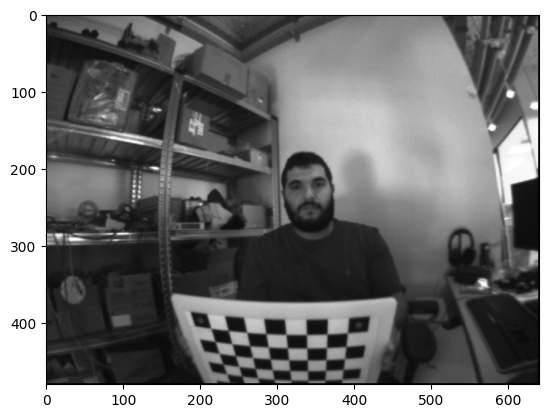

In [64]:
img = imgs[10].copy()
plt.imshow(img, cmap='gray')

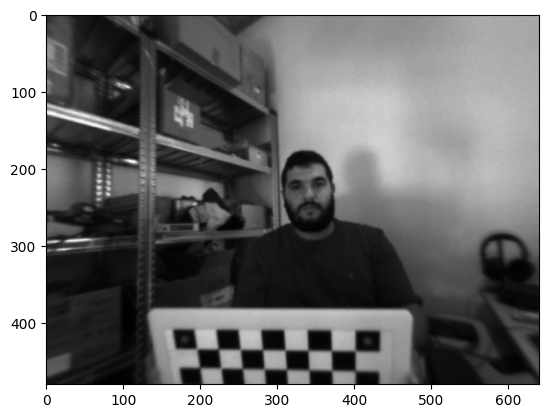

In [65]:
plt.imshow(undistort(img, K, D, DIM), cmap='gray')

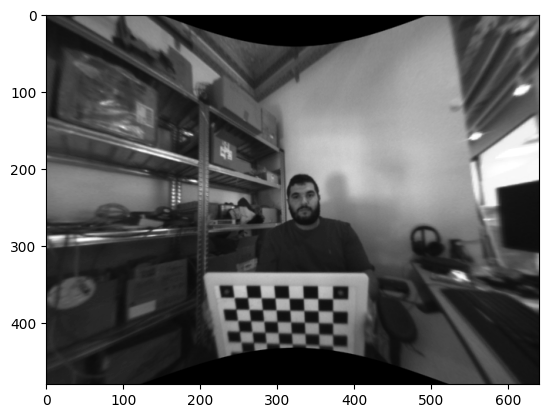

In [66]:
plt.imshow(undistort_upd(img, K, D, DIM, 0.8), cmap='gray')